In [1]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA 1: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaría en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y milímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc.

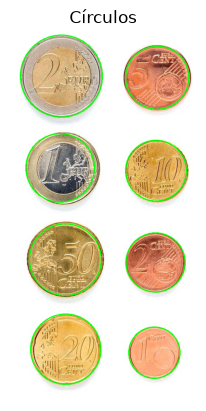

(938, 473)
Contorno: 180 puntos, Area: 13090.0, Perimetro: 428.6173162460327, Diametro: 129.0995958188223, Compacidad: 14.034591580286603
Contorno: 244 puntos, Area: 24594.0, Perimetro: 587.8132734298706, Diametro: 176.9577728250912, Compacidad: 14.049135741251519
Contorno: 228 puntos, Area: 17452.0, Perimetro: 496.9015808105469, Diametro: 149.0656785940951, Compacidad: 14.148016331195304
Contorno: 260 puntos, Area: 25740.0, Perimetro: 601.4701204299927, Diametro: 181.03365952629665, Compacidad: 14.05463503380225
Contorno: 212 puntos, Area: 18388.0, Perimetro: 508.21528816223145, Diametro: 153.0108778766731, Compacidad: 14.046268170644982
Contorno: 260 puntos, Area: 23522.0, Perimetro: 576.4995613098145, Diametro: 173.058199953832, Compacidad: 14.129399889057414
Contorno: 244 puntos, Area: 19854.0, Perimetro: 529.8721466064453, Diametro: 158.9933895518047, Compacidad: 14.141457225210148
Contorno: 308 puntos, Area: 33654.0, Perimetro: 689.0680999755859, Diametro: 207.00145805891603, Com

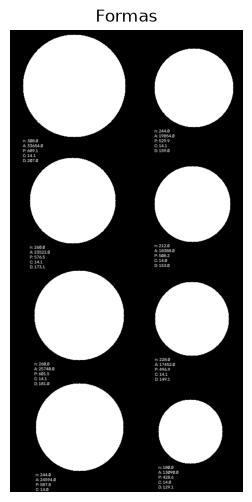

In [ ]:
#Imagen ideal
#Carga imagen ejemplo con monedas
img = cv2.imread('Monedas.jpg') 
#Recordar que OpenCV lee las imágenes en BGR, por lo que convertimos para visualizr a RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


#Conversión a gris
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
#Suaviza imagen (elimina altas frecuencias)
pimg = cv2.medianBlur(gris, 7)
#Localiza Círculos
circ = cv2.HoughCircles(
        pimg,  # imagen 
        cv2.HOUGH_GRADIENT,  # tipo de detección
        1,
        100,  # distancia mínima entre círculos
        param1=100, # valor del gradiente
        param2=50, # umbral acumulador
        minRadius=50,  # radio mínimo
        maxRadius=150,  # radio máximo
    )

#Dibuja sobre entrada e imagen vacía
img_cont = np.zeros(img_rgb.shape, dtype=np.uint8)
img_cont = cv2.cvtColor(img_cont, cv2.COLOR_BGR2GRAY)
for det in circ[0]:
        x_coor, y_coor, det_radio = det
        cv2.circle(img_rgb,(int(x_coor), int(y_coor)),
            int(det_radio),(0, 255, 0), 2)
        cv2.circle(img_cont,(int(x_coor), int(y_coor)),
            int(det_radio),(255, 255, 255), -1)

#Muestra resultado
plt.subplot(121)
plt.axis("off")
plt.imshow(img_rgb) 
plt.title('Círculos')

plt.show()

print(img_cont.shape)

# Localiza contornos
contours, _ = cv2.findContours(img_cont, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)


# Parámeros texto
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 0.3
thickness = 1

mm_coins_2 = []
# Process each contour to calculate compactness and ellipse ratio (if possible)
for c in contours:
    # Puntos del contorno
    clon = len(c)

    # Área y perímetro
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)

    #Contenedor alineado con ejes de la imagen
    x,y,w,h = cv2.boundingRect(c)
    
    # Compactness: 4*pi*Area/Perimeter^2
    if perimetro > 0:
        compacidad = (perimetro ** 2) / area
    else:
        compactness = 0

    #diametro = 2 * np.sqrt(area / np.pi)
    if area > 0:
        diametro = 2 * np.sqrt(area / np.pi)
        mm_coins_2.append(diametro)

    
    # Muestra valores en imageb
    cv2.putText(img_cont, f"n: {clon:.1f}", (x, int(y+h+10)), font, font_scale, (255, 255, 255), thickness)
    cv2.putText(img_cont, f"A: {area:.1f}", (x, int(y+h+20)), font, font_scale, (255, 255, 255), thickness)
    cv2.putText(img_cont, f"P: {perimetro:.1f}", (x, int(y+h+30)), font, font_scale, (255, 255, 255), thickness)
    cv2.putText(img_cont, f"C: {compacidad:.1f}", (x, int(y+h+40)), font, font_scale, (255, 255, 255), thickness)  
    cv2.putText(img_cont, f"D: {diametro:.1f}", (x, int(y+h+50)), font, font_scale, (255, 255, 255), thickness)  

    print(f"Contorno: {clon} puntos, Area: {area}, Perimetro: {perimetro}, Diametro: {diametro}, Compacidad: {compacidad}")


razon = 25.75 / max(mm_coins_2)

for i in range(len(mm_coins_2)):
    mm_coins_2[i] = np.abs(mm_coins_2[i] * razon)

dict = {
    'Moneda': [0.01, 0.02, 0.05, 0.10, 0.20, 0.50, 1.00, 2.00], 
    'Diametro (mm)': [16.25, 18.75, 21.25, 19.75, 22.25, 24.25, 23.25, 25.75], 
}

sum = 0

for mm in mm_coins_2:
    closest_coin = min(dict['Diametro (mm)'], key=lambda x: abs(x - mm))
    coin_index = dict['Diametro (mm)'].index(closest_coin)
    coin_value = dict['Moneda'][coin_index]
    sum += coin_value
    print(f"Diámetro medido: {mm:.2f} mm, Moneda más cercana: {coin_value:.2f} €")

print(f"Valor total de las monedas: {sum:.2f} €")

# Visualiza la imagen
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(img_cont, cv2.COLOR_BGR2RGB))
plt.title("Formas")
plt.axis('off')
plt.show()


In [ ]:
#Cámara

TAREA 2: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo